Uncomment the cell below if python modules need installing

In [1]:
# pip install --upgrade numpy pandas scikit-learn matplotlib fg-data-profiling ipywidgets

Importing libraries

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn import preprocessing
from matplotlib import pyplot
from data_profiling import ProfileReport
%matplotlib inline
import matplotlib.pyplot as plt

Loading the dataset used for the practical, doing some basic exploration using pandas profiling

In [3]:
# Load the dataset, X = input data y = class labels
data = pd.read_csv("checkerboard.csv")
#print(data)

# On google colab the profile report for the full dataset is too large, and it won't be shown
data_reduced = data.drop(data.columns[range(5,20)],axis=1)
profile = ProfileReport(data_reduced, title='Profiling Report')
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:00<00:00, 1025.79it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

From the report above we may notice a few things. Attributes 3 and 4  look different from the rest. They don't show a normal distribution nor correlation to other attributes. Let's inspect them more closely.

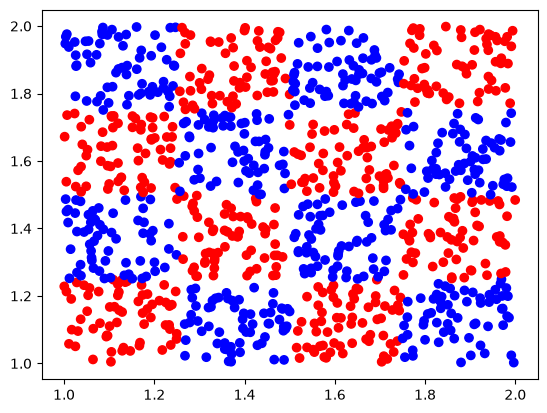

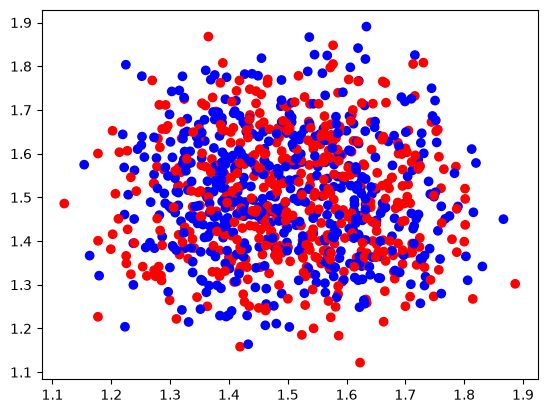

In [4]:
plt.scatter(data['att3'], data['att4'],c=data['class'])
plt.show()

plt.scatter(data['att1'], data['att5'],c=data['class'])
plt.show()

This reveals the true nature of this dataset. It is just a checkerboard pattern specified by features 'att3' and 'att4'. All other features are irrelevant features initialised from a gaussian function. You may think that any machine learning algorithm may have an easy job in this dataset. Let's see about that.

In [5]:
#Transform the dataset into numerical X and y matrices that can be processed by scikit-learn
X = data.iloc[:,:-1].values
#X = data.iloc[:,[2,3]].values
y = data.iloc[:,-1].values
# Class labels are strings in this case, and have to be converted to integers
le = preprocessing.LabelEncoder()
y = le.fit_transform(y)

In the next cell you see two possible ML pipelines based on different classifiers (RandomForestClassifier and KNeighborsClassifier). Comment/uncomment each block of lines to enable/disable each of the three options

In [6]:
# Create a Random Forest classifier and initialise the parameters for its grid search
classifier = RandomForestClassifier()
# Params dictionary of random forest
param_grid = dict(max_depth=[2,3,4],n_estimators = [100, 200, 500])

# Similarly for a K-nearest neighbours classifier
#classifier = KNeighborsClassifier()
#param_grid = dict(n_neighbors=[2,3,4,5,10])

The next cell runs the 5-fold stratified cross-validation process. For RandomForest and KNN a nested cross-validation process is run to tune the methods using grid search. After a model has been trained we evaluate it using the test set by generating F1 scores, and extracting the confidence of the predictions to (later) be able to generate a Precision-Recall curve

In [7]:
scores = []
preds = []
actual_labels = []
# Initialise the 5-fold cross-validation
kf = StratifiedKFold(n_splits=5,shuffle=True)
for train_index,test_index in kf.split(X,y):
	# Generate the training and test partitions of X and Y for each iteration of CV
	X_train, X_test = X[train_index], X[test_index]
	y_train, y_test = y[train_index], y[test_index]

	# Increasing the value of the verbose parameter will give more messags of the internal grid search process
	# Increasing n_jobs will tell it to use multiple cores to parallelise the computation
	grid_search = GridSearchCV(classifier,param_grid=param_grid,cv=5,scoring="f1",verbose=0,n_jobs=4)
	grid_search.fit(X_train,y_train)

	# Printing the values of the parameters chosen by grid search
	estimator = grid_search.best_estimator_
    # Uncomment the next two lines if you are using the RandomForest classifier
	print("Chosen max depth: {0}".format(estimator.max_depth))
	print("Chosen number of trees: {0}".format(estimator.n_estimators))
    # Uncomment the next line if using the KNN classifier
	#print("Number of neighbours: {0}".format(estimator.n_neighbors))

	# Predicting the test data with the optimised models
	predictions = estimator.predict(X_test)
	score = metrics.f1_score(y_test,predictions)
	scores.append(score)

	# Extract the probabiliites of predicting the 2nd class, which will use to generate the PR curve
	probs = estimator.predict_proba(X_test)[:,1]
	preds.extend(probs)
	actual_labels.extend(y_test)

Chosen max depth: 2
Chosen number of trees: 500
Chosen max depth: 2
Chosen number of trees: 200
Chosen max depth: 2
Chosen number of trees: 200
Chosen max depth: 2
Chosen number of trees: 100
Chosen max depth: 2
Chosen number of trees: 100


Generation of the overall performance scores and plots

Average F1 score: 0.5195674561508566
AUPRC score: 0.5251272951679067


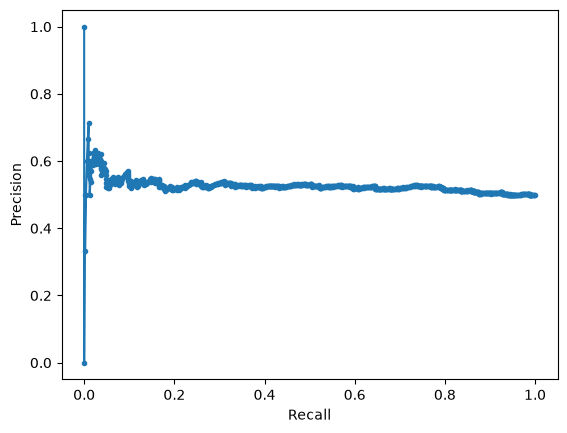

In [8]:
# Report the overall F1 score
print("Average F1 score: {0}".format(np.average(scores)))

prec, recall, _ = metrics.precision_recall_curve(actual_labels, preds)
print("AUPRC score: {0}".format(metrics.auc(recall,prec)))
# Generate the PR curve
plt.plot(recall, prec, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

As you can see, the performance is very poor for all methods in this notebook. We need proper data pre-processing (feature selection) to be able to solve this problem, as will be seen in later lectures/practicals. Do you want to make the life of the ML pipelines easier? Create a version of X that only contains the relevant features by uncommenting '#X = data.iloc[:,[2,3]].values' in cell 4 and re-run all three pipelines.